In [1]:

import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex":True,
    "font.family":"Helvetica",
    "font.size"  : 13,
})

# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import from_numpy
from sklearn.model_selection import train_test_split

from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.cuda.empty_cache()
# device = 'cpu'
# Set the plotting style
#plt.style.use('seaborn-poster')

from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from os import listdir
from os.path import isfile, join

from copy import deepcopy

#from getdist import MCSamples, plots

import pickle as pk

from hyperparameters import hparams, hparams_cnn

In [2]:
torch.cuda.empty_cache()

In [3]:
import sys
sys.path.append('./src')
from hyperparameters import hparams
from C3NN import C3NN
from load_data import load_data_wide
from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn
import numpy as np
import random
from torch import from_numpy
import torch
import time, datetime
import cloudpickle as cpk

In [4]:
training_parameters, training_data = load_data_wide(hparams)

In [9]:
# first naive model
class Regressor(nn.Module):
    def __init__(self, hidden_dim):
        super(Regressor, self).__init__()
        #self.c3nn = C3NN(hparams)#.to(device='cuda')

        self.conv1 = nn.Conv2d(4, 32, kernel_size=5, stride=1, padding=2)  # -> 32 feature maps
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2)          # -> 64 feature maps
        self.conv3 = nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2)          # -> 64 feature maps
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # halve H and W each time
        
        
        #self.fc1 = nn.Linear(hparams.order*hparams.num_filts, hidden_dim)
        self.fc1 = nn.Linear(64, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc3 = nn.Linear(hidden_dim, 3)
        self.avg = nn.AdaptiveAvgPool2d((1,1))
        
        self.parallel = torch.vmap(self.forward_single, in_dims=0, out_dims=0)

    def forward(self, x):
        print(x.shape)   # [B, 150, 4, 50, 50]
        x = torch.mean(self.parallel(x), 1)
        print(x.shape) # (B,64,6,6)
        x = self.avg(x)
        print(x.shape)
        #x = self.parallel(x)
        x = x.view(x.size(0), -1)
        #x = self.c3nn(x)
        x = self.fc1(x)      # first linear layer
        x = self.relu(x)     # activation
        x = self.fc2(x)      # first linear layer
        x = self.relu(x)     # activation
        x = self.fc3(x)      # output layer
        return x

    def forward_single(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        return x

model = Regressor(64).to('cuda')

In [5]:
# CNN we've been using thus far
from hyperparameters import hparams_cnn
from CNN import CNNEmbedding
hparams_cnn.bottleneck=3
model = CNNEmbedding(hparams_cnn)

In [10]:
# optimized version of the naive CNN
import torch
import torch.nn as nn
import torch.nn.functional as F

class RegressorOptimized(nn.Module):
    def __init__(self, hidden_dim: int = 256, in_channels: int = 4, mlp_dropout: float = 0.1):
        super().__init__()
        # ---- Conv stack (2 stages) ----
        # Larger first kernel to catch large-scale patterns, then smaller.
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=7, stride=1, padding=3, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2, bias=False)
        self.bn2   = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Make FC input independent of spatial size
        self.gap   = nn.AdaptiveAvgPool2d((1, 1))

        # ---- MLP head ----
        self.fc1   = nn.Linear(64, hidden_dim)
        self.fc2   = nn.Linear(hidden_dim, hidden_dim)
        self.fc3   = nn.Linear(hidden_dim, 8)
        self.act   = nn.ReLU(inplace=True)
        self.drop  = nn.Dropout(p=mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()

        # Init
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    # Per-realization feature extractor
    def forward_single(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool1(self.act(self.bn1(self.conv1(x))))
        x = self.pool2(self.act(self.bn2(self.conv2(x))))
        x = self.gap(x)                   # [B,64,1,1]
        x = torch.flatten(x, 1)           # [B,64]
        return x

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Accepts [B,R,C,H,W] (R=realizations) or [B,C,H,W].
        Averages features across realizations before the MLP.
        """
        if x.dim() == 5:                  # [B,R,C,H,W]
            B, R, C, H, W = x.shape
            x = x.view(B * R, C, H, W)
            feats = self.forward_single(x)        # [B*R, 64]
            feats = feats.view(B, R, -1).mean(1)  # [B, 64]
        elif x.dim() == 4:                # [B,C,H,W]
            feats = self.forward_single(x)        # [B, 64]
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.fc1(feats)
        z = self.act(z)
        z = self.drop(z)
        z = self.fc2(z)
        z = self.act(z)
        z = self.drop(z)
        out = self.fc3(z)                 # [B, 8]
        return out

model = RegressorOptimized()

In [4]:
#optimzed version including escnn symmetries (doesnt work)
# try again now with bias -> still doesn't work

import torch
import torch.nn as nn
import torch.nn.functional as F
import escnn
from escnn import nn as escnn_nn
import escnn.gspaces as gspaces
from escnn.nn.modules.batchnormalization import GNormBatchNorm

class RegressorESCNNInvariant(nn.Module):
    """
    Two ESCNN R2Conv stages (rotation-invariant via trivial reps) -> GAP -> MLP -> 8 outputs.
    Accepts [B,R,C,H,W] or [B,C,H,W]; averages across R if present.
    """
    def __init__(
        self,
        gspace,                 # e.g., escnn.gspaces.Rot2dOnR2(N) or ContinuousRot2dOnR2()
        in_channels: int = 4,
        c1: int = 32,
        c2: int = 64,
        k1: int = 7,
        k2: int = 5,
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
    ):
        super().__init__()
        self.gspace = gspace
        self.in_channels = in_channels
        self.c1, self.c2 = int(c1), int(c2)
        self.k1, self.k2 = int(k1), int(k2)

        # --- Field types with trivial representations (rotation-invariant channels) ---
        in_type   = escnn_nn.FieldType(gspace, in_channels * [gspace.trivial_repr])
        mid_type  = escnn_nn.FieldType(gspace, self.c1       * [gspace.trivial_repr])
        out_type  = escnn_nn.FieldType(gspace, self.c2       * [gspace.trivial_repr])

        # --- Stage 1: R2Conv (stride=2) + BN + ReLU ---
        self.conv1 = escnn_nn.R2Conv(
            in_type=in_type, out_type=mid_type,
            kernel_size=self.k1, padding=self.k1 // 2, stride=2, bias=True
        )
        #self.bn1   = escnn_nn.PointwiseBatchNorm(mid_type) (GPT mistake)
        #self.bn1 = GNormBatchNorm(mid_type) throws error
        self.act1  = escnn_nn.ReLU(mid_type)

        # --- Stage 2: R2Conv (stride=2) + BN + ReLU ---
        self.conv2 = escnn_nn.R2Conv(
            in_type=mid_type, out_type=out_type,
            kernel_size=self.k2, padding=self.k2 // 2, stride=2, bias=True
        )
        #self.bn2   = escnn_nn.PointwiseBatchNorm(out_type) (GPT mistake)
        #self.bn2 = GNormBatchNorm(mid_type)
        self.act2  = escnn_nn.ReLU(out_type)

        # --- Head: GAP (spatial) -> MLP -> 8 ---
        self.gap   = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1   = nn.Linear(self.c2, hidden_dim)
        self.fc2   = nn.Linear(hidden_dim, hidden_dim)
        self.fc3   = nn.Linear(hidden_dim, 8)
        self.drop  = nn.Dropout(p=mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act   = nn.ReLU(inplace=True)

        self.apply(self._init_weights)

        # Save input type for wrapping tensors
        self._in_type  = in_type

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        # ESCNN layers come with suitable defaults; no extra init needed here.

    # --- ESCNN feature extractor on a batch tensor [B, C, H, W] ---
    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        # Wrap to GeometricTensor with the declared input type
        x = escnn_nn.GeometricTensor(x_bchw, self._in_type)

        x = self.conv1(x)
        #x = self.bn1(x)
        x = self.act1(x)

        x = self.conv2(x)
        #x = self.bn2(x)
        x = self.act2(x)

        # unwrap to plain tensor for spatial pooling and MLP head
        x_t = x.tensor                      # [B, c2, H', W']
        x_t = self.gap(x_t)                 # [B, c2, 1, 1]
        x_t = torch.flatten(x_t, 1)         # [B, c2]
        return x_t

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [B,R,C,H,W] or [B,C,H,W]
        Returns: [B, 8]
        """
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            x = x.view(B * R, C, H, W)
            feats = self._features(x)               # [B*R, c2]
            feats = feats.view(B, R, -1).mean(1)    # average across realizations
        elif x.dim() == 4:
            feats = self._features(x)               # [B, c2]
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.fc1(feats)
        z = self.act(z)
        z = self.drop(z)
        z = self.fc2(z)
        z = self.act(z)
        z = self.drop(z)
        out = self.fc3(z)                           # [B, 8]
        return out

gspace = gspaces.rot2dOnR2(N=-1,maximum_frequency=6)
model = RegressorESCNNInvariant(gspace)

In [8]:
# patch one (seems to always fail)
import torch
import torch.nn as nn
from escnn import nn as escnn_nn
from escnn import gspaces
from escnn.nn.modules.batchnormalization import GNormBatchNorm


class RegressorESCNN_GroupPool(nn.Module):
    """
    Two equivariant R2Conv blocks (regular reps of C_N) -> GroupPooling (invariant) -> GAP -> MLP -> 8.
    Accepts [B,R,C,H,W] or [B,C,H,W]; averages over R.
    """
    def __init__(
        self,
        gspace,                  # e.g. gspaces.Rot2dOnR2(N=16)
        in_channels: int = 4,
        c1: int = 16,
        c2: int = 32,
        k1: int = 7,
        k2: int = 5,
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
    ):
        super().__init__()
        self.gspace = gspace

        # Field types: input scalars (trivial), hidden regular reps, then group-pool to trivial
        self.in_type   = escnn_nn.FieldType(gspace, in_channels * [gspace.trivial_repr])
        self.hid1_type = escnn_nn.FieldType(gspace, c1 * [gspace.regular_repr])
        self.hid2_type = escnn_nn.FieldType(gspace, c2 * [gspace.regular_repr])

        # Block 1 (bias=False since BN follows)
        self.conv1 = escnn_nn.R2Conv(self.in_type, self.hid1_type,
                                     kernel_size=int(k1), padding=int(k1)//2, stride=2, bias=False)
        self.bn1  = GNormBatchNorm(self.hid1_type)
        self.act1 = escnn_nn.ReLU(self.hid1_type)

        # Block 2
        self.conv2 = escnn_nn.R2Conv(self.hid1_type, self.hid2_type,
                                     kernel_size=int(k2), padding=int(k2)//2, stride=2, bias=False)
        self.bn2  = GNormBatchNorm(self.hid2_type)
        self.act2 = escnn_nn.ReLU(self.hid2_type)

        # Rotation invariance
        self.gpool    = escnn_nn.GroupPooling(self.hid2_type)  # -> trivial reps
        self.out_type = self.gpool.out_type

        # Spatial summary
        self.gap = nn.AdaptiveAvgPool2d(1)

        # MLP head
        c_out = self.out_type.size
        self.fc1  = nn.Linear(c_out, hidden_dim)
        self.fc2  = nn.Linear(hidden_dim, hidden_dim)
        self.fc3  = nn.Linear(hidden_dim, 8)
        self.drop = nn.Dropout(mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act  = nn.ReLU(inplace=True)

        # Init linears
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    @staticmethod
    def _safe_flatten(x: torch.Tensor) -> torch.Tensor:
        # Works for non-contiguous tensors
        x = x.reshape(x.size(0), -1)
        return x

    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        # Wrap as GeometricTensor
        gx = escnn_nn.GeometricTensor(x_bchw, self.in_type)

        gx = self.act1(self.bn1(self.conv1(gx)))   # -> hid1_type
        gx = self.act2(self.bn2(self.conv2(gx)))   # -> hid2_type
        gx = self.gpool(gx)                        # -> out_type (trivial reps)

        # Unwrap and make contiguous before any shape ops
        x = gx.tensor.contiguous()                 # [B, C_out, H', W']
        x = self.gap(x)                            # [B, C_out, 1, 1]
        x = self._safe_flatten(x)                  # [B, C_out]
        return x

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            x_r = x.reshape(B * R, C, H, W)        # reshape is safe for non-contiguous
            feats = self._features(x_r)            # [B*R, C_out]
            feats = feats.reshape(B, R, -1).mean(dim=1)
        elif x.dim() == 4:
            feats = self._features(x)
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.act(self.fc1(feats)); z = self.drop(z)
        z = self.act(self.fc2(z)); z = self.drop(z)
        out = self.fc3(z)
        return out


# Example: finite rotation group C_N (regular_repr requires finite groups)
gspace = gspaces.rot2dOnR2(N=16)
model = RegressorESCNN_GroupPool(gspace)


In [5]:
# mean + std instead of meaning over realizations (still escnn)

import torch
import torch.nn as nn
from escnn import nn as escnn_nn
from escnn import gspaces


class RegressorESCNNInvariant(nn.Module):
    """
    Two ESCNN R2Conv stages (trivial reps -> rotation-invariant channels) -> GAP -> Stat-pool over R (mean+std) -> MLP -> 8.
    Accepts [B,R,C,H,W] or [B,C,H,W]. For [B,C,H,W], std is filled with zeros so the head stays the same shape.
    """
    def __init__(
        self,
        gspace,                 # e.g., gspaces.Rot2dOnR2(N) or ContinuousRot2dOnR2()
        in_channels: int = 4,
        c1: int = 32,
        c2: int = 64,
        k1: int = 7,
        k2: int = 5,
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
    ):
        super().__init__()
        self.gspace = gspace
        self.in_channels = in_channels
        self.c1, self.c2 = int(c1), int(c2)
        self.k1, self.k2 = int(k1), int(k2)

        # --- Field types with trivial representations (rotation-invariant channels) ---
        self.in_type  = escnn_nn.FieldType(gspace, in_channels * [gspace.trivial_repr])
        self.mid_type = escnn_nn.FieldType(gspace, self.c1     * [gspace.trivial_repr])
        self.out_type = escnn_nn.FieldType(gspace, self.c2     * [gspace.trivial_repr])

        # --- Stage 1: R2Conv (stride=2) + ReLU (bias=True since no BN) ---
        self.conv1 = escnn_nn.R2Conv(
            in_type=self.in_type, out_type=self.mid_type,
            kernel_size=self.k1, padding=self.k1 // 2, stride=2, bias=True
        )
        self.act1  = escnn_nn.ReLU(self.mid_type)

        # --- Stage 2: R2Conv (stride=2) + ReLU ---
        self.conv2 = escnn_nn.R2Conv(
            in_type=self.mid_type, out_type=self.out_type,
            kernel_size=self.k2, padding=self.k2 // 2, stride=2, bias=True
        )
        self.act2  = escnn_nn.ReLU(self.out_type)

        # --- Spatial summary and head ---
        self.gap   = nn.AdaptiveAvgPool2d((1, 1))
        # mean+std doubles the channel dimension -> 2*c2
        self.fc1   = nn.Linear(2 * self.c2, hidden_dim)
        self.fc2   = nn.Linear(hidden_dim, hidden_dim)
        self.fc3   = nn.Linear(hidden_dim, 8)
        self.drop  = nn.Dropout(p=mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act   = nn.ReLU(inplace=True)

        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    # --- ESCNN feature extractor on a batch tensor [B, C, H, W] ---
    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        # Wrap to GeometricTensor with the declared input type
        x = escnn_nn.GeometricTensor(x_bchw, self.in_type)

        x = self.conv1(x); x = self.act1(x)     # -> mid_type
        x = self.conv2(x); x = self.act2(x)     # -> out_type

        # unwrap to plain tensor for spatial pooling and MLP head
        x_t = x.tensor.contiguous()             # [B, c2, H', W']
        x_t = self.gap(x_t)                     # [B, c2, 1, 1]
        x_t = x_t.reshape(x_t.size(0), -1)      # [B, c2]
        return x_t

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [B,R,C,H,W] or [B,C,H,W]
        Returns: [B, 8]
        """
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            x = x.reshape(B * R, C, H, W)
            feats = self._features(x)                 # [B*R, c2]
            feats = feats.reshape(B, R, -1)           # [B, R, c2]
            mu = feats.mean(dim=1)                    # [B, c2]
            sd = feats.std(dim=1, unbiased=False)     # [B, c2]
            summary = torch.cat([mu, sd], dim=1)      # [B, 2*c2]
        elif x.dim() == 4:
            feats = self._features(x)                 # [B, c2]
            # For R=1, use zeros for std so the head still expects 2*c2
            sd = torch.zeros_like(feats)
            summary = torch.cat([feats, sd], dim=1)   # [B, 2*c2]
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.act(self.fc1(summary)); z = self.drop(z)
        z = self.act(self.fc2(z));       z = self.drop(z)
        out = self.fc3(z)                 # [B, 8]
        return out


# Example gspace (continuous rotations are fine with trivial reps):
#   For continuous: gspaces.Rot2dOnR2(N=-1, maximum_frequency=6)
#   For discrete C_N: gspaces.Rot2dOnR2(N=16)
gspace = gspaces.rot2dOnR2(N=-1, maximum_frequency=6)
model = RegressorESCNNInvariant(gspace)

In [30]:
# given that mean+std worked so much better, let's try attention for combination over realizations:
#(you can set attn mean or stat)
# best one I think
import torch
import torch.nn as nn
from escnn import nn as escnn_nn
from escnn import gspaces


class RealizationAttention(nn.Module):
    """
    x: [B, R, D] -> returns weighted sum over R: [B, D]
    """
    def __init__(self, d_in: int, d_hidden: int = 64, temperature: float = 1.0):
        super().__init__()
        d_hidden = max(1, int(d_hidden))
        self.scorer = nn.Sequential(
            nn.Linear(d_in, d_hidden),
            nn.ReLU(inplace=True),
            nn.Linear(d_hidden, 1)
        )
        self.register_buffer("temperature", torch.tensor(float(temperature)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, R, D]
        scores = self.scorer(x)                    # [B, R, 1]
        attn = torch.softmax(scores / self.temperature, dim=1)  # [B, R, 1]
        return (attn * x).sum(dim=1)               # [B, D]


class RegressorESCNNInvariant(nn.Module):
    """
    ESCNN trunk (trivial reps -> rotation-invariant channels) -> GAP
    -> pool realizations (attn | stat | mean) -> MLP -> 8.
    Accepts [B,R,C,H,W] or [B,C,H,W].
    """
    def __init__(
        self,
        gspace,                 # e.g., gspaces.Rot2dOnR2(N=-1, maximum_frequency=6) or gspaces.Rot2dOnR2(N=16)
        in_channels: int = 4,
        c1: int = 32,
        c2: int = 64,
        k1: int = 7,
        k2: int = 5,
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
        pooling_mode: str = "attn",     # "attn" | "stat" | "mean"
        attn_hidden: int = 64,
        attn_temperature: float = 1.0,
    ):
        super().__init__()
        self.gspace = gspace
        self.c2 = int(c2)
        self.pooling_mode = pooling_mode.lower()

        # --- Field types with trivial (scalar) reps (rotation invariance per channel) ---
        self.in_type  = escnn_nn.FieldType(gspace, int(in_channels) * [gspace.trivial_repr])
        self.mid_type = escnn_nn.FieldType(gspace, int(c1)         * [gspace.trivial_repr])
        self.out_type = escnn_nn.FieldType(gspace, self.c2         * [gspace.trivial_repr])

        # --- Two equivariant conv stages (bias=True because no BN) ---
        self.conv1 = escnn_nn.R2Conv(self.in_type,  self.mid_type,
                                     kernel_size=int(k1), padding=int(k1)//2, stride=2, bias=True)
        self.act1  = escnn_nn.ReLU(self.mid_type)

        self.conv2 = escnn_nn.R2Conv(self.mid_type, self.out_type,
                                     kernel_size=int(k2), padding=int(k2)//2, stride=2, bias=True)
        self.act2  = escnn_nn.ReLU(self.out_type)

        # --- Spatial summary ---
        self.gap = nn.AdaptiveAvgPool2d(1)

        # --- Realization pooling ---
        if self.pooling_mode == "attn":
            self.poolR = RealizationAttention(self.c2, d_hidden=attn_hidden, temperature=attn_temperature)
            fc1_in = self.c2
        elif self.pooling_mode == "stat":
            # mean + std concatenation
            self.poolR = None
            fc1_in = 2 * self.c2
        elif self.pooling_mode == "mean":
            self.poolR = None
            fc1_in = self.c2
        else:
            raise ValueError(f"Unknown pooling_mode '{pooling_mode}'. Use 'attn', 'stat', or 'mean'.")

        # --- Head ---
        self.fc1  = nn.Linear(fc1_in, hidden_dim)
        self.fc2  = nn.Linear(hidden_dim, hidden_dim)
        self.fc3  = nn.Linear(hidden_dim, 8)
        self.drop = nn.Dropout(p=mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act  = nn.ReLU(inplace=True)

        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    # --- ESCNN feature extractor on [B, C, H, W] -> [B, c2] ---
    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        x = escnn_nn.GeometricTensor(x_bchw, self.in_type)
        x = self.act1(self.conv1(x))        # -> mid_type
        x = self.act2(self.conv2(x))        # -> out_type
        t = x.tensor.contiguous()           # [B, c2, H', W']
        t = self.gap(t)                     # [B, c2, 1, 1]
        t = t.reshape(t.size(0), -1)        # [B, c2]
        return t

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            x_ = x.reshape(B * R, C, H, W)
            feats = self._features(x_)                   # [B*R, c2]
            per_real = feats.reshape(B, R, -1)           # [B, R, c2]

            if self.pooling_mode == "attn":
                summary = self.poolR(per_real)           # [B, c2]
            elif self.pooling_mode == "stat":
                mu = per_real.mean(dim=1)                # [B, c2]
                sd = per_real.std(dim=1, unbiased=False) # [B, c2]
                summary = torch.cat([mu, sd], dim=1)     # [B, 2*c2]
            else:  # mean
                summary = per_real.mean(dim=1)           # [B, c2]

        elif x.dim() == 4:
            feats = self._features(x)                    # [B, c2]
            if self.pooling_mode == "stat":
                sd = torch.zeros_like(feats)
                summary = torch.cat([feats, sd], dim=1)  # [B, 2*c2]
            else:
                summary = feats                          # [B, c2]
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.act(self.fc1(summary)); z = self.drop(z)
        z = self.act(self.fc2(z));       z = self.drop(z)
        out = self.fc3(z)                 # [B, 8]
        return out


# Example gspace (continuous or discrete both OK with trivial reps)
gspace = gspaces.rot2dOnR2(N=-1, maximum_frequency=3)   # continuous
#gspace = gspaces.rot2dOnR2(N=16)                          # discrete C_N
model = RegressorESCNNInvariant(gspace, pooling_mode="attn", attn_hidden=64, attn_temperature=1.0)


In [ ]:
# try a bit larger? (not tried yet)

gspace = gspaces.rot2dOnR2(N=-1, maximum_frequency=6)   # continuous
model = RegressorESCNNInvariant(gspace, pooling_mode="attn", attn_hidden=64, attn_temperature=1.0)

In [38]:
# try more convs
import torch
import torch.nn as nn
from escnn import nn as escnn_nn
from escnn import gspaces

class RegressorESCNNInvariant_LargeScale(nn.Module):
    """
    ESCNN trunk (trivial reps, rotation-invariant channels):
      conv1 (stride=2) -> conv2 (stride=2, optional dilation) -> optional conv3 (VALID padding) -> GAP
      -> (R pooling outside here, or plug your mean/stat/attn) -> MLP -> 8
    Accepts [B,R,C,H,W] or [B,C,H,W].
    """
    def __init__(
        self,
        gspace,
        in_channels: int = 4,
        c1: int = 32,
        c2: int = 64,
        k1: int = 9,              # a bit larger first kernel
        k2: int = 5,
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
        use_dilated_conv2: bool = True,
        conv2_dilation: int = 2,  # grow RF without more params
        add_valid_conv3: bool = True,
        c3: int = 64,
        k3: int = 5,              # valid conv → padding=0
    ):
        super().__init__()
        self.c2 = int(c2)
        self.add_valid_conv3 = bool(add_valid_conv3)

        # Field types (trivial reps everywhere = invariant per channel)
        self.in_type  = escnn_nn.FieldType(gspace, int(in_channels) * [gspace.trivial_repr])
        self.mid_type = escnn_nn.FieldType(gspace, int(c1)         * [gspace.trivial_repr])
        self.out2_type= escnn_nn.FieldType(gspace, self.c2         * [gspace.trivial_repr])

        # ---- conv1: bigger kernel, stride=2, bias=True (no BN) ----
        self.conv1 = escnn_nn.R2Conv(self.in_type, self.mid_type,
                                     kernel_size=int(k1), stride=2, padding=int(k1)//2, bias=True)
        self.act1  = escnn_nn.ReLU(self.mid_type)

        # ---- conv2: optional dilation to enlarge RF ----
        dil = int(conv2_dilation) if use_dilated_conv2 else 1
        pad2 = (int(k2) // 2) * dil
        self.conv2 = escnn_nn.R2Conv(self.mid_type, self.out2_type,
                                     kernel_size=int(k2), stride=2, padding=pad2, dilation=dil, bias=True)
        self.act2  = escnn_nn.ReLU(self.out2_type)

        # ---- optional conv3: VALID padding (padding=0) to bias to large scales & reduce borders ----
        if self.add_valid_conv3:
            self.out3_type = escnn_nn.FieldType(gspace, int(c3) * [gspace.trivial_repr])
            self.conv3 = escnn_nn.R2Conv(self.out2_type, self.out3_type,
                                         kernel_size=int(k3), stride=1, padding=0, bias=True)  # VALID
            self.act3  = escnn_nn.ReLU(self.out3_type)
            head_c = int(c3)
        else:
            self.out3_type = None
            head_c = self.c2

        # ---- spatial pooling & head ----
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.fc1  = nn.Linear(head_c, hidden_dim)
        self.fc2  = nn.Linear(hidden_dim, hidden_dim)
        self.fc3  = nn.Linear(hidden_dim, 8)
        self.drop = nn.Dropout(mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act  = nn.ReLU(inplace=True)

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        gx = escnn_nn.GeometricTensor(x_bchw, self.in_type)
        gx = self.act1(self.conv1(gx))         # -> mid_type
        gx = self.act2(self.conv2(gx))         # -> out2_type
        if self.add_valid_conv3:
            gx = self.act3(self.conv3(gx))     # -> out3_type

        t = gx.tensor.contiguous()             # [B, C, H, W]
        t = self.gap(t)                        # [B, C, 1, 1]
        t = t.reshape(t.size(0), -1)           # [B, C]
        return t

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            xr = x.reshape(B * R, C, H, W)
            feats = self._features(xr)               # [B*R, D]
            summary = feats.reshape(B, R, -1).mean(1)  # keep mean over R for now
        elif x.dim() == 4:
            summary = self._features(x)
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.act(self.fc1(summary)); z = self.drop(z)
        z = self.act(self.fc2(z));       z = self.drop(z)
        return self.fc3(z)

gspace = gspaces.rot2dOnR2(N=-1, maximum_frequency=2)   # continuous
model = RegressorESCNNInvariant_LargeScale(gspace, mlp_dropout=0.0)

In [52]:
# 3 convs, with attention
import torch
import torch.nn as nn
from escnn import nn as escnn_nn
from escnn import gspaces


class RealizationAttention(nn.Module):
    """
    x: [B, R, D] -> weighted sum over realizations: [B, D]
    """
    def __init__(self, d_in: int, d_hidden: int = 64, temperature: float = 1.0):
        super().__init__()
        self.scorer = nn.Sequential(
            nn.Linear(d_in, max(1, d_hidden)),
            nn.ReLU(inplace=True),
            nn.Linear(max(1, d_hidden), 1)
        )
        self.register_buffer("temperature", torch.tensor(float(temperature)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, R, D]
        scores = self.scorer(x)                       # [B, R, 1]
        attn = torch.softmax(scores / self.temperature, dim=1)  # [B, R, 1]
        return (attn * x).sum(dim=1)                  # [B, D]


class RegressorESCNNInvariant_LargeScale_Attn(nn.Module):
    """
    ESCNN trunk (trivial reps -> rotation-invariant channels):
      conv1 (stride=2) ->
      conv2 (stride=2, optional dilation) ->
      optional conv3 (VALID padding) ->
      GAP ->
      pool realizations (attn | stat | mean) ->
      MLP -> 8

    Accepts [B,R,C,H,W] or [B,C,H,W].
    """
    def __init__(
        self,
        gspace,
        in_channels: int = 4,
        c1: int = 32,
        c2: int = 64,
        # conv kernels
        k1: int = 9,
        k2: int = 5,
        k3: int = 5,                 # used if add_valid_conv3=True
        # dilation / valid conv controls
        use_dilated_conv2: bool = True,
        conv2_dilation: int = 2,
        add_valid_conv3: bool = True,
        c3: int = 64,
        # head
        hidden_dim: int = 256,
        mlp_dropout: float = 0.1,
        # realization pooling
        pooling_mode: str = "attn",  # "attn" | "stat" | "mean" | "stat+attn"
        attn_hidden: int = 64,
        attn_temperature: float = 1.0,
    ):
        super().__init__()
        self.add_valid_conv3 = bool(add_valid_conv3)
        self.pooling_mode = pooling_mode.lower()

        # ---------- field types (trivial reps everywhere) ----------
        self.in_type   = escnn_nn.FieldType(gspace, int(in_channels) * [gspace.trivial_repr])
        self.mid_type  = escnn_nn.FieldType(gspace, int(c1)         * [gspace.trivial_repr])
        self.out2_type = escnn_nn.FieldType(gspace, int(c2)         * [gspace.trivial_repr])

        # ---------- conv1 ----------
        self.conv1 = escnn_nn.R2Conv(
            self.in_type, self.mid_type,
            kernel_size=int(k1), stride=2, padding=int(k1)//2, bias=True
        )
        self.act1 = escnn_nn.ReLU(self.mid_type)

        # ---------- conv2 (optional dilation) ----------
        dil = int(conv2_dilation) if use_dilated_conv2 else 1
        pad2 = (int(k2)//2) * dil
        self.conv2 = escnn_nn.R2Conv(
            self.mid_type, self.out2_type,
            kernel_size=int(k2), stride=2, padding=pad2, dilation=dil, bias=True
        )
        self.act2 = escnn_nn.ReLU(self.out2_type)

        # ---------- optional conv3 (VALID padding) ----------
        if self.add_valid_conv3:
            self.out3_type = escnn_nn.FieldType(gspace, int(c3) * [gspace.trivial_repr])
            self.conv3 = escnn_nn.R2Conv(
                self.out2_type, self.out3_type,
                kernel_size=int(k3), stride=1, padding=0, bias=True  # VALID
            )
            self.act3 = escnn_nn.ReLU(self.out3_type)
            head_c = int(c3)
        else:
            self.out3_type = None
            head_c = int(c2)

        # ---------- spatial summary ----------
        self.gap = nn.AdaptiveAvgPool2d(1)

        # ---------- realization pooling ----------
        if self.pooling_mode == "attn":
            self.poolR = RealizationAttention(head_c, d_hidden=attn_hidden, temperature=attn_temperature)
            fc1_in = head_c
        elif self.pooling_mode == "stat":
            self.poolR = None
            fc1_in = 2 * head_c                      # concat mean & std
        elif self.pooling_mode == "stat+attn":
            self.poolR = RealizationAttention(head_c, d_hidden=attn_hidden, temperature=attn_temperature)
            fc1_in = 3 * head_c                      # [mean, std, attn]
        elif self.pooling_mode == "mean":
            self.poolR = None
            fc1_in = head_c
        else:
            raise ValueError(f"Unknown pooling_mode '{pooling_mode}'")

        # ---------- MLP head ----------
        self.fc1  = nn.Linear(fc1_in, hidden_dim)
        self.fc2  = nn.Linear(hidden_dim, hidden_dim)
        self.fc3  = nn.Linear(hidden_dim, 8)
        self.drop = nn.Dropout(mlp_dropout) if mlp_dropout and mlp_dropout > 0 else nn.Identity()
        self.act  = nn.ReLU(inplace=True)

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    # ----- ESCNN trunk on [B,C,H,W] -> [B, D] -----
    def _features(self, x_bchw: torch.Tensor) -> torch.Tensor:
        gx = escnn_nn.GeometricTensor(x_bchw, self.in_type)
        gx = self.act1(self.conv1(gx))      # -> mid_type
        gx = self.act2(self.conv2(gx))      # -> out2_type
        if self.add_valid_conv3:
            gx = self.act3(self.conv3(gx))  # -> out3_type

        t = gx.tensor.contiguous()          # [B, D, H', W']
        t = self.gap(t)                     # [B, D, 1, 1]
        t = t.reshape(t.size(0), -1)        # [B, D]
        return t

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.dim() == 5:
            B, R, C, H, W = x.shape
            xr = x.reshape(B * R, C, H, W)
            feats = self._features(xr)                # [B*R, D]
            per_real = feats.reshape(B, R, -1)        # [B, R, D]

            if self.pooling_mode == "attn":
                summary = self.poolR(per_real)        # [B, D]
            elif self.pooling_mode == "stat":
                mu = per_real.mean(1)
                sd = per_real.std(1, unbiased=False)
                summary = torch.cat([mu, sd], dim=1)  # [B, 2D]
            elif self.pooling_mode == "stat+attn":
                mu = per_real.mean(1)
                sd = per_real.std(1, unbiased=False)
                attn = self.poolR(per_real)
                summary = torch.cat([mu, sd, attn], dim=1)  # [B, 3D]
            else:  # mean
                summary = per_real.mean(1)            # [B, D]

        elif x.dim() == 4:
            feats = self._features(x)                 # [B, D]
            if self.pooling_mode == "stat":
                sd = torch.zeros_like(feats)
                summary = torch.cat([feats, sd], dim=1)
            elif self.pooling_mode == "stat+attn":
                # With R=1, attn reduces to identity; still form [mean, std, attn]
                sd = torch.zeros_like(feats)
                summary = torch.cat([feats, sd, feats], dim=1)
            else:
                summary = feats
        else:
            raise ValueError(f"Expected [B,R,C,H,W] or [B,C,H,W], got {tuple(x.shape)}")

        z = self.act(self.fc1(summary)); z = self.drop(z)
        z = self.act(self.fc2(z));       z = self.drop(z)
        return self.fc3(z)

gspace = gspaces.rot2dOnR2(N=-1, maximum_frequency=6)   # continuous
model = RegressorESCNNInvariant_LargeScale_Attn(gspace, pooling_mode="stat+attn", attn_hidden=64, attn_temperature=1.0)

In [6]:
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from torch import nn, optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import copy
import math

def train_model(model, train_loader, val_loader, device,
                num_epochs=100,
                criterion=None,
                optimizer=None,
                lr=1e-3,
                # Early stopping:
                es_patience=10,
                es_min_delta=0.0,
                # LR scheduler on plateau:
                lr_factor=0.1,
                lr_patience=5,
                lr_min=1e-6,
                lr_threshold=1e-4):
    """
    Trains a regression model with MSE loss and reports MSE, RMSE, and MAE.
    Adds: Early stopping (on val MSE) and ReduceLROnPlateau scheduler.

    Returns:
        model (best weights restored), history (list of dicts per epoch)
    """
    model = model.to(device)
    if criterion is None:
        criterion = nn.MSELoss()
    if optimizer is None:
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=lr_factor,
        patience=lr_patience,
        threshold=lr_threshold,
        threshold_mode='rel',
        min_lr=lr_min,
        verbose=False
    )

    print('Starting Training...')
    best_val = math.inf
    best_state = copy.deepcopy(model.state_dict())
    es_counter = 0
    history = []

    for epoch in range(num_epochs):
        # -------- TRAIN --------
        model.train()
        train_mse_sum, train_mae_sum, n_train = 0.0, 0.0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            pred = model(x)
            loss = criterion(pred, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            with torch.no_grad():
                bsz = y.size(0)
                n_train += bsz
                train_mse_sum += torch.mean((pred - y) ** 2).item() * bsz
                train_mae_sum += torch.mean(torch.abs(pred - y)).item() * bsz

        train_mse = train_mse_sum / n_train
        train_rmse = train_mse ** 0.5
        train_mae = train_mae_sum / n_train

        # -------- VALIDATION --------
        model.eval()
        val_mse_sum, val_mae_sum, n_val = 0.0, 0.0, 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = model(x)
                val_mse_sum += torch.mean((pred - y) ** 2).item() * y.size(0)
                val_mae_sum += torch.mean(torch.abs(pred - y)).item() * y.size(0)
                n_val += y.size(0)

        val_mse = val_mse_sum / n_val
        val_rmse = val_mse ** 0.5
        val_mae = val_mae_sum / n_val

        # ---- Scheduler step on validation metric ----
        scheduler.step(val_mse)
        current_lr = optimizer.param_groups[0]['lr']

        # ---- Logging ----
        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train: MSE {train_mse:.6f} | RMSE {train_rmse:.6f} | MAE {train_mae:.6f} || "
            f"Val: MSE {val_mse:.6f} | RMSE {val_rmse:.6f} | MAE {val_mae:.6f} || "
            f"LR: {current_lr:.2e}"
        )

        history.append({
            "epoch": epoch + 1,
            "train_mse": train_mse, "train_rmse": train_rmse, "train_mae": train_mae,
            "val_mse": val_mse, "val_rmse": val_rmse, "val_mae": val_mae,
            "lr": current_lr
        })

        # ---- Early stopping (on val_mse) ----
        if val_mse < (best_val - es_min_delta):
            best_val = val_mse
            best_state = copy.deepcopy(model.state_dict())
            es_counter = 0
        else:
            es_counter += 1
            if es_counter >= es_patience:
                print(f"Early stopping triggered at epoch {epoch+1}. Best val MSE: {best_val:.6f}")
                break

    # restore best weights
    model.load_state_dict(best_state)
    return model, history


In [10]:
# ----------------------------
# Convert tensors to Datasets & Loaders
# ----------------------------
X_train, X_val, y_train, y_val = train_test_split(training_data, training_parameters, test_size=0.1, random_state=42)

y_train_mean = y_train.mean(0)
y_train_std = y_train.std(0)
y_train_stand = (y_train - y_train_mean) / y_train_std
y_val_stand = (y_val - y_train_mean) / y_train_std

#sys.exit()
train_dataset = TensorDataset(X_train, y_train_stand)
val_dataset = TensorDataset(X_val, y_val_stand)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
device = 'cuda'
model, history = train_model(model, train_loader, val_loader, device, num_epochs=1, lr=1e-2, es_patience=20)

Starting Training...
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4, 50, 50])
torch.Size([16, 64, 6, 6])
torch.Size([16, 64, 1, 1])
torch.Size([16, 150, 4

In [8]:
# ----------------------------
# Convert tensors to Datasets & Loaders
# ----------------------------
X_train, X_val, y_train, y_val = train_test_split(training_data, training_parameters, test_size=0.1, random_state=42)

y_train_mean = y_train.mean(0)
y_train_std = y_train.std(0)
y_train_stand = (y_train - y_train_mean) / y_train_std
y_val_stand = (y_val - y_train_mean) / y_train_std

#sys.exit()
train_dataset = TensorDataset(X_train, y_train_stand)
val_dataset = TensorDataset(X_val, y_val_stand)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
device = 'cuda'
model, history = train_model(model, train_loader, val_loader, device, num_epochs=200, lr=1e-2, es_patience=20)
# large model CNN: 0.622
# naive model CNN: 0.68
# naive model smaller filters, avg pool: 0.71
# regressor optimized: .64, val .61
# escnn did not work until I used mean+std instead: .73 .7 val
# does this mean attention might work wonders? no: .74 .7
# I am very confused, the following are no longer reproducible, apparently it is without dropout
# best one by far: frequency=3 3 convs escnn: .66 .63
# freq 1 doesnt work at all 1.; 2 better .67 .63; 3 doesnt work at all

Starting Training...
Epoch [1/200] Train: MSE 1.010822 | RMSE 1.005396 | MAE 0.846266 || Val: MSE 0.970522 | RMSE 0.985151 | MAE 0.824521 || LR: 1.00e-02
Epoch [2/200] Train: MSE 0.897153 | RMSE 0.947182 | MAE 0.791701 || Val: MSE 1.000008 | RMSE 1.000004 | MAE 0.816974 || LR: 1.00e-02
Epoch [3/200] Train: MSE 0.724362 | RMSE 0.851095 | MAE 0.690790 || Val: MSE 0.762999 | RMSE 0.873498 | MAE 0.705375 || LR: 1.00e-02
Epoch [4/200] Train: MSE 0.722192 | RMSE 0.849819 | MAE 0.689506 || Val: MSE 0.729000 | RMSE 0.853815 | MAE 0.684789 || LR: 1.00e-02
Epoch [5/200] Train: MSE 0.694204 | RMSE 0.833189 | MAE 0.673132 || Val: MSE 0.721043 | RMSE 0.849142 | MAE 0.673828 || LR: 1.00e-02
Epoch [6/200] Train: MSE 0.684473 | RMSE 0.827329 | MAE 0.663538 || Val: MSE 0.768562 | RMSE 0.876677 | MAE 0.710697 || LR: 1.00e-02
Epoch [7/200] Train: MSE 0.679774 | RMSE 0.824484 | MAE 0.664934 || Val: MSE 0.697322 | RMSE 0.835058 | MAE 0.654813 || LR: 1.00e-02
Epoch [8/200] Train: MSE 0.639764 | RMSE 0.79985

In [ ]:
# ----------------------------
# Convert tensors to Datasets & Loaders
# ----------------------------
X_train, X_val, y_train, y_val = train_test_split(training_data, training_parameters, test_size=0.1, random_state=42)

y_train_mean = y_train.mean(0)
y_train_std = y_train.std(0)
y_train_stand = (y_train - y_train_mean) / y_train_std
y_val_stand = (y_val - y_train_mean) / y_train_std

#sys.exit()
train_dataset = TensorDataset(X_train, y_train_stand)
val_dataset = TensorDataset(X_val, y_val_stand)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
device = 'cuda'
model, history = train_model(model, train_loader, val_loader, device, num_epochs=200, lr=1e-2, es_patience=20)

In [9]:
%matplotlib inline
def plot_regression_predictions(y_true, y_pred, feature_names=None):
    """
    Plots prediction vs truth for each dimension of a multi-output regression.

    Args:
        y_true: torch.Tensor or np.ndarray of shape (N, D) with ground truth values
        y_pred: torch.Tensor or np.ndarray of shape (N, D) with predictions
        feature_names: list of strings for axis labels, length D (optional)
    """

    # Convert to numpy if torch tensors
    if hasattr(y_true, "detach"):
        y_true = y_true.detach().cpu().numpy()
    if hasattr(y_pred, "detach"):
        y_pred = y_pred.detach().cpu().numpy()

    D = y_true.shape[1]
    ncols = 4
    nrows = int(np.ceil(D / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = axes.flatten()

    for d in range(D):
        ax = axes[d]
        ax.scatter(y_true[:, d], y_pred[:, d], alpha=0.6)
        min_val = min(y_true[:, d].min(), y_pred[:, d].min())
        max_val = max(y_true[:, d].max(), y_pred[:, d].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'r--')  # y=x line
        label = feature_names[d] if feature_names else f"Dim {d+1}"
        ax.set_title(f"Prediction vs Truth: {label}")
        ax.set_xlabel("Truth")
        ax.set_ylabel("Prediction")

    # Remove unused subplots if any
    for d in range(D, len(axes)):
        fig.delaxes(axes[d])

    plt.tight_layout()
    #plt.savefig('Plots/mse_testing.png')

In [10]:
import cloudpickle as cpk
with open(f"/project/ag-weller/Kai.Lehman/C3NN_Models/MSE_Models/naive_165k_1k_examples.cpk", "wb") as handle:
    cpk.dump(model, handle)


In [ ]:
'hello'

In [40]:
import cloudpickle as cpk
hparams_cnn.bottleneck=8
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/MSE_Models/{hparams_cnn.name_model()}.cpk', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/MSE_Models/3convs_bandwidth2_p63.cpk', 'rb') as f:
    model = cpk.load(f)

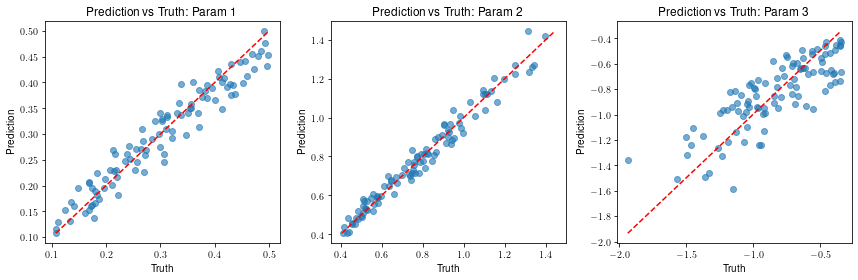

In [16]:
# Suppose y_true and y_pred are torch tensors of shape (N, 8)
model.eval()
#y_pred = model(X_val)
val_dataset = TensorDataset(X_val, y_val_stand)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)
y_pred = np.empty(0)
for params, data in val_loader:
    y_pred = np.append(y_pred,model(params).detach().cpu().numpy())
y_pred = torch.tensor(y_pred).view((-1,3)).detach().cpu()
y_val_raw = y_val * y_train_std + y_train_mean
y_pred_raw = y_pred * y_train_std.to('cpu') + y_train_mean.to('cpu')
plot_regression_predictions(y_val, y_pred_raw,
                            feature_names=[f"Param {i+1}" for i in range(8)])

#plt.savefig('Plots/naive_optimized_mse.png', facecolor='w')
plt.show()

In [44]:
ae = torch.abs(y_val_raw.cpu() - y_pred_raw.cpu())
se = ae**2
print(torch.mean(ae[:,0]))
print(torch.mean(se[:,0]))
# large CNN 0.0329, 0.0017
# naive CNN 0.0357, 0.0020

tensor(0.0276, dtype=torch.float64)
tensor(0.0012, dtype=torch.float64)


In [20]:
sum(p.numel() for p in model.parameters() if p.requires_grad)
# large CNN: 102,873,352
# naive CNN: 370,536
# escnn: 107,624

165475

In [18]:
print(y_train_mean,y_train_std)

tensor([ 0.2983,  0.8237, -0.8990], device='cuda:0') tensor([0.1058, 0.2602, 0.3489], device='cuda:0')


In [22]:
training_parameters_mean

tensor([ 0.2987,  0.8201, -0.8926], device='cuda:0')

In [23]:
training_parameters_std

tensor([0.1061, 0.2593, 0.3483], device='cuda:0')

In [ ]:
print(y_val-y_pred)

In [ ]:
print('still alive')

In [ ]:
# in the next step I could use the extracted summaries to train sbi now...